# 03E - Going further: the logistic equation

**MATH 331 - Differential Equations.** Lecture plan: after Sessions 7 and 8 (a solution that stops; a numerical method that invents oscillations; a bifurcation).

**This notebook is optional.** It goes beyond what the course asks. Read notebook 03 first.

**References**
* J. Lebl, *Notes on Diffy Qs*: Section 1.6 (autonomous equations, harvesting; Figures
  1.6.5-1.6.7), Example 1.2.3 ($y' = y^2$), Section 1.5 (Bernoulli equations), Section 1.7
  (Euler's method).
* J.D. Logan, *An Introduction to Nonlinear Partial Differential Equations*, 2nd ed. (Wiley,
  2008), Section 7.4.1 (harvesting and the bifurcation diagram).
* Related notebooks: 03, 04 and 13 (Euler's method), 11 (existence), 12 (Bernoulli equations).

**What you will see**
1. A logistic solution that goes to infinity in a **finite** time.
2. The same solution found another way, as a Bernoulli equation.
3. Euler's method inventing oscillations that the true solution never has.
4. The harvest at which two equilibria meet and disappear: a **bifurcation**.

In this notebook the step of Euler's method is written $\Delta t$, because $h$ is the harvest.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: logistic_solution, logistic_blowup_time, euler, harvesting_equilibria, phase_line, slope_field).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. A negative start: the solution stops

A population cannot be negative, but the equation $x' = kx(M - x)$ does not know it. The phase
line of notebook 03 says that a solution with $x_0 < 0$ falls. How fast? The formula

$$ x(t) = \frac{M\,x_0}{x_0 + (M - x_0)\,e^{-kMt}} $$

holds for every $x_0$ (it was checked by substitution in notebook 03). For $x_0 < 0$ the
denominator starts at $M > 0$ and decreases towards $x_0 < 0$: it **vanishes** at

$$ t^* = \frac{1}{kM}\,\ln\frac{M - x_0}{-x_0} > 0 , $$

and there $x \to -\infty$. The solution exists only for $t < t^*$, although the right-hand side
is a harmless polynomial. It is the phenomenon of $y' = y^2$ (Lebl, Example 1.2.3; notebooks 09
and 11): Picard's theorem promises a solution near the starting point, not for ever.

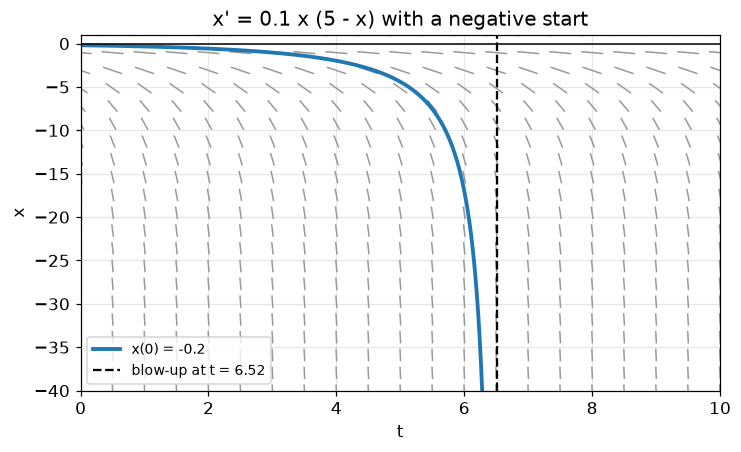

In [2]:
K_LEBL, M_LEBL = 0.1, 5.0                   # Lebl, Figure 1.6.2
FIGURE_SIZE = (7.5, 4.2)
N_POINTS = 600
NEGATIVE_START = -0.2
LONG_TIME = 10.0
DEPTH = -40.0                               # the picture is cut here
BEFORE = 0.999                              # the curve is drawn up to this fraction of the blow-up time


def plot_negative_start(x0=NEGATIVE_START, t_end=LONG_TIME):
    # a solution with x(0) < 0, and the time at which it goes to minus infinity
    blow_up = ol.logistic_blowup_time(x0, K_LEBL, M_LEBL)
    times = np.linspace(0.0, min(t_end, BEFORE * blow_up), N_POINTS)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, lambda tt, xx: K_LEBL * xx * (M_LEBL - xx), (0.0, t_end), (DEPTH, 1.0))
    ax.plot(times, ol.logistic_solution(times, x0, K_LEBL, M_LEBL), "-", linewidth=2.5, label=f"x(0) = {x0:g}")
    ax.axvline(blow_up, linestyle="--", color="black", label=f"blow-up at t = {blow_up:.2f}")
    ax.axhline(0.0, color="black", linewidth=1)
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.set_title("x' = 0.1 x (5 - x) with a negative start")
    ax.legend(loc="lower left")
    plt.show()


plot_negative_start()
assert np.isclose(ol.logistic_blowup_time(NEGATIVE_START, K_LEBL, M_LEBL), 6.516, atol=0.001)

*The plot shows* the solution that starts from $-0.2$: it leaves the axis slowly, then falls
faster and faster and dives out of the picture just before the dashed vertical line $t = 6.52$,
which it never reaches.

**Slider.** Before moving it: does a start further from zero blow up sooner or later?

In [3]:
NEGATIVE_RANGE = (-3.0, -0.05, 0.05)        # minimum, maximum, step

interact(plot_negative_start,
         x0=FloatSlider(value=NEGATIVE_START, min=NEGATIVE_RANGE[0], max=NEGATIVE_RANGE[1], step=NEGATIVE_RANGE[2],
                        description="x(0)", continuous_update=False),
         t_end=FloatSlider(value=LONG_TIME, min=2.0, max=20.0, step=1.0, description="t max",
                           continuous_update=False));

interactive(children=(FloatSlider(value=-0.2, continuous_update=False, description='x(0)', max=-0.05, min=-3.0...

(Sooner: from $-1$ the blow-up is at $t = 3.58$. Close to zero the solution lingers near the
unstable equilibrium for a long time.)

## 2. Another route: a Bernoulli equation

Written as $x' - kM\,x = -k\,x^2$, the logistic equation is a **Bernoulli** equation with $n = 2$
(notebook 12; Lebl, Section 1.5). The substitution $v = x^{1-n} = 1/x$ gives $v' = -x'/x^2$, that is

$$ v' + kM\,v = k , $$

a **linear** equation, and of the simplest kind (notebook 13): $v$ relaxes to $v_\infty = 1/M$
with time constant $\tau = 1/(kM)$,

$$ v(t) = \frac1M + \Big(\frac{1}{x_0} - \frac1M\Big)e^{-kMt} . $$

So $1/x$ approaches $1/M$ exponentially, and $x = 1/v$ is the formula of Section 1. A negative
start means a negative $v(0)$, which must cross zero on its way to $1/M > 0$: where $v = 0$,
$x = 1/v$ is infinite. That is the blow-up.

In [4]:
t = sp.symbols("t", nonnegative=True)
k, M = sp.symbols("k M", positive=True)
x_0 = sp.symbols("x_0", nonzero=True)

v = 1 / M + (1 / x_0 - 1 / M) * sp.exp(-k * M * t)
formula = M * x_0 / (x_0 + (M - x_0) * sp.exp(-k * M * t))
print("v solves v' + k M v = k:", sp.simplify(sp.diff(v, t) + k * M * v - k) == 0)
print("1 / v is the logistic formula:", sp.simplify(1 / v - formula) == 0)

assert sp.simplify(sp.diff(v, t) + k * M * v - k) == 0 and sp.simplify(1 / v - formula) == 0

v solves v' + k M v = k: True
1 / v is the logistic formula: True


## 3. Euler's method invents oscillations

Euler's method (notebooks 13 and 04) with step $\Delta t$ on the logistic equation:

$$ x_{n+1} = x_n + \Delta t\;k\,x_n\,(M - x_n) . $$

Near the stable equilibrium write $x_n = M + e_n$ and drop $e_n^2$:
$\;e_{n+1} \approx (1 - \Delta t\,kM)\,e_n$. The same factor as in notebook 13, with
$\tau = 1/(kM)$. So, once the computed values are close to $M$:

* $\Delta t\,kM < 1$: the error shrinks without changing sign, like the true solution;
* $1 < \Delta t\,kM < 2$: the factor is negative: the computed values **jump across $M$**, while
  the true solution never crosses it;
* $\Delta t\,kM > 2$: the computed values do not settle at all. They hop between two values,
  then four, then without any pattern (the *logistic map*); for still larger steps, or a start far
  above $M$, they run away to $-\infty$.

None of this is in the differential equation. It is all made by the method.

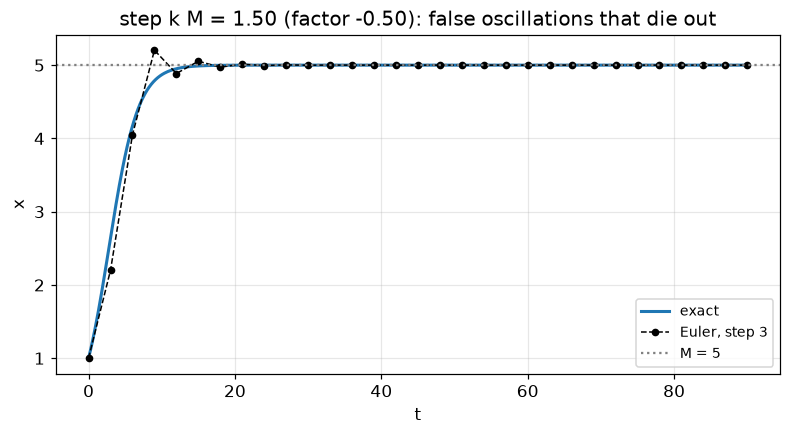

In [5]:
WIDE_FIGURE = (8.5, 4.0)
START = 1.0
DEFAULT_PRODUCT = 1.5                       # the value of  (step) x k x M
DEFAULT_STEPS = 30


def plot_euler_logistic(product=DEFAULT_PRODUCT, x0=START, n_steps=DEFAULT_STEPS):
    # Euler's values for the logistic equation of Lebl, for a given value of step * k * M
    step = product / (K_LEBL * M_LEBL)
    try:
        t_euler, x_euler = ol.euler(lambda tt, xx: K_LEBL * xx * (M_LEBL - xx), (0.0, n_steps * step), x0, step)
    except FloatingPointError:                 # the values ran away to infinity
        print(f"step k M = {product:.2f}, x(0) = {x0:g}: Euler's values run away to infinity. "
              "Try a smaller step or a smaller x(0).")
        return
    times = np.linspace(0.0, n_steps * step, N_POINTS)
    if product <= 1:
        what = "no oscillation near M"
    elif product <= 2:
        what = "false oscillations that die out"
    else:
        what = "the computed values never settle"
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(times, ol.logistic_solution(times, x0, K_LEBL, M_LEBL), "-", linewidth=2, label="exact")
    ax.plot(t_euler, x_euler, "o--", color="black", markersize=4, linewidth=1, label=f"Euler, step {step:.3g}")
    ax.axhline(M_LEBL, linestyle=":", color="gray", label="M = 5")
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.set_title(f"step k M = {product:.2f} (factor {1 - product:+.2f}): {what}")
    ax.legend(loc="lower right")
    plt.show()


plot_euler_logistic()

# the three regimes, checked on the last computed values
for product, settles in ((0.5, True), (1.5, True), (2.2, False)):
    step = product / (K_LEBL * M_LEBL)
    values = ol.euler(lambda tt, xx: K_LEBL * xx * (M_LEBL - xx), (0.0, 60 * step), START, step)[1]
    assert np.isclose(values[-1], M_LEBL, atol=1e-6) == settles

*The plot shows* the exact solution (solid curve), rising smoothly to the dotted line $x = 5$,
and Euler's values with a step of 3 (black dots joined by a dashed line): they overshoot 5 at
the third step, come back below it, and zigzag around it with smaller and smaller jumps.

**Slider.** Before moving it: with $k = 0.1$ and $M = 5$, which is the largest step for which the
computed values do not cross $x = 5$? What do you expect for the product 2.2?

In [6]:
PRODUCT_RANGE = (0.1, 2.9, 0.05)            # minimum, maximum, step
START_RANGE = (0.1, 9.0, 0.1)
STEP_COUNTS = (5, 100)

interact(plot_euler_logistic,
         product=FloatSlider(value=DEFAULT_PRODUCT, min=PRODUCT_RANGE[0], max=PRODUCT_RANGE[1], step=PRODUCT_RANGE[2],
                             description="step k M", continuous_update=False),
         x0=FloatSlider(value=START, min=START_RANGE[0], max=START_RANGE[1], step=START_RANGE[2],
                        description="x(0)", continuous_update=False),
         n_steps=IntSlider(value=DEFAULT_STEPS, min=STEP_COUNTS[0], max=STEP_COUNTS[1], description="steps",
                           continuous_update=False));

interactive(children=(FloatSlider(value=1.5, continuous_update=False, description='step k M', max=2.9, min=0.1...

(The product must be at most 1: a step of 2. For 2.2 the values end up hopping for ever between
3.73 and 5.81, neither of which is an equilibrium of the equation.)

## 4. The bifurcation

With harvesting, $x' = kx(M - x) - h$, the equilibria are (notebook 03)

$$ A,\ B = \frac{kM \pm \sqrt{(kM)^2 - 4hk}}{2k} . $$

Plot them against the harvest $h$: the **bifurcation diagram**. As $h$ grows the stable
equilibrium $A$ comes down, the unstable one $B$ comes up, they meet at $h_c = kM^2/4$ and
vanish. A change of this kind in the *number* of equilibria is called a **bifurcation** (this
one, a *saddle-node* bifurcation).

**Stable, unstable, or half of each?** At $h = h_c$ the single equilibrium $x = M/2$ attracts the
solutions from above and repels those from below. Lebl calls it unstable, and rightly: an
equilibrium is stable only if **all** nearby solutions stay near. Many books say *semi-stable*.
The quick test is silent here, because $f'(M/2) = 0$: the sign of $f$ on each side decides.

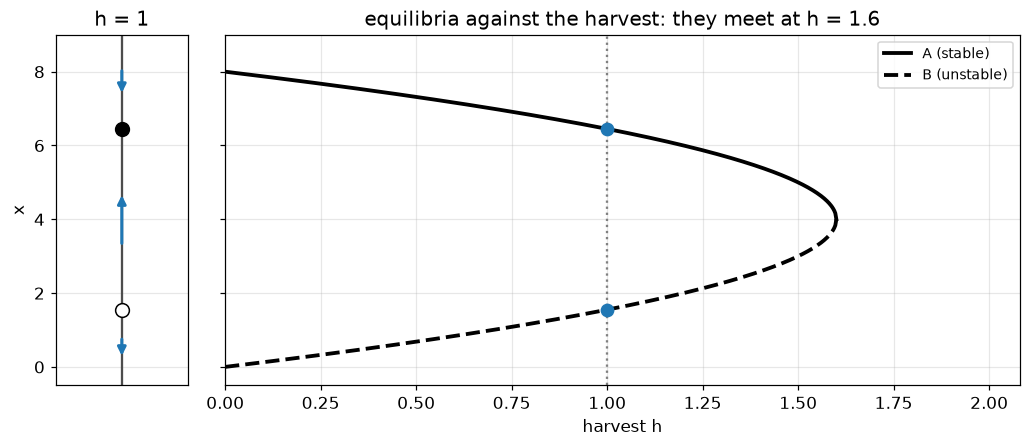

In [7]:
K_HARVEST, M_HARVEST = 0.1, 8.0             # Lebl's example
TWO_PANELS = (9.5, 4.2)
BEYOND = 1.3                                # the diagram is drawn up to 1.3 times the critical harvest
DEFAULT_HARVEST = 1.0


def plot_bifurcation(h=DEFAULT_HARVEST):
    # the phase line for one harvest, and the equilibria for every harvest
    critical = K_HARVEST * M_HARVEST ** 2 / 4
    window = (-0.5, M_HARVEST + 1.0)
    equilibria = ol.harvesting_equilibria(K_HARVEST, M_HARVEST, h)
    harvests = np.linspace(0.0, critical, N_POINTS)
    root = np.sqrt(np.maximum((K_HARVEST * M_HARVEST) ** 2 - 4 * harvests * K_HARVEST, 0.0))
    fig, (line_ax, ax) = plt.subplots(1, 2, figsize=TWO_PANELS, sharey=True, gridspec_kw={"width_ratios": (1, 6)})
    ol.phase_line(line_ax, lambda value: K_HARVEST * value * (M_HARVEST - value) - h, list(equilibria), window)
    line_ax.set_ylabel("x")
    line_ax.set_title(f"h = {h:g}")
    ax.plot(harvests, (K_HARVEST * M_HARVEST + root) / (2 * K_HARVEST), "-", color="black", linewidth=2.5, label="A (stable)")
    ax.plot(harvests, (K_HARVEST * M_HARVEST - root) / (2 * K_HARVEST), "--", color="black", linewidth=2.5,
            label="B (unstable)")
    ax.axvline(h, linestyle=":", color="gray")
    for level in equilibria:
        ax.plot(h, level, "o", color="tab:blue", markersize=8)
    ax.set_xlim(0.0, BEYOND * critical)
    ax.set_xlabel("harvest h")
    ax.set_title(f"equilibria against the harvest: they meet at h = {critical:g}")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_bifurcation()

*The plot shows*, on the right, the two equilibria against the harvest: the solid curve $A$
starts at 8 and comes down, the dashed curve $B$ starts at 0 and goes up; they join at the point
$(1.6,\ 4)$, and to the right of it there is nothing. The dotted vertical line marks the harvest
chosen, $h = 1$, and the two blue dots are its equilibria, 6.45 and 1.55. On the left, the phase
line for that harvest.

**Slider.** Move the harvest towards 1.6 and beyond. Before: what happens to the distance between
the stable population and the "point of no return" $B$?

In [8]:
HARVEST_RANGE = (0.0, 2.0, 0.05)            # minimum, maximum, step

interact(plot_bifurcation,
         h=FloatSlider(value=DEFAULT_HARVEST, min=HARVEST_RANGE[0], max=HARVEST_RANGE[1], step=HARVEST_RANGE[2],
                       description="h", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='h', max=2.0, step=0.05), Ou...

(It shrinks to zero: near the critical harvest the stable population sits just above the level
below which everything collapses. A small extra catch, or one bad season, is enough.)

## 5. Problems

Ordinary problems, without automatic checks.

1. Solve the logistic equation as a Bernoulli equation (Section 2): show that $v = 1/x$ satisfies
   $v' = -kMv + k$, solve it, and recover the formula.
2. Show that the largest growth rate is $kM^2/4$, at $x = M/2$. Why is the critical harvest the
   same number?
3. For $x_0 < 0$, check on the formula that $x(t) \to -\infty$ as $t \to t^*$ from the left. Why
   does this not contradict Picard's theorem?
4. Euler's method on the logistic equation with $k = 0.1$, $M = 5$: find the largest step for
   which the computed values do not oscillate. Confirm with the slider of Section 3.
5. Draw by hand the phase line of $x' = x^2\,(x - 2)$. Classify each equilibrium. For which one is
   the quick test silent?

<details>
<summary>Final answers (after trying)</summary>

2. $f(x) = kx(M - x)$ is a parabola with its vertex at $x = M/2$, where $f = kM^2/4$. An
   equilibrium with harvest needs $f(x) = h$, impossible when $h$ is above the vertex.
3. The theorem gives a solution on *some* interval around $t = 0$; it does not say how long.
4. Step 2 (the product $\Delta t\,kM$ equal to 1).
5. $x = 2$ is unstable ($f' = 4 > 0$). At $x = 0$, $f' = 0$: the test is silent; $f < 0$ on both
   sides, so solutions come down to 0 from above and leave it downwards: semi-stable (unstable).

</details>